# 03 · Dimensionality reduction and ANOVA feature ranking
**Paper:** Sec. III C (128 → 18 manual reduction, Eqs. 3–5), Sec. IV A, Table III  
**Code:** `ann_entanglement.features`, `ann_entanglement.selection`

In [1]:
import os, sys
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
sys.path.insert(0, os.path.abspath("../src"))  # not needed after `pip install -e .`
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3)

In [2]:
from ann_entanglement import dataset, selection, features
train = dataset.generate_training_set(n_per_class=2000, seed=0)   # 12 x 10^3 states, as in the paper
print(len(features.FULL_128), '->', len(features.CANONICAL_18), 'features'); train.head()

128 -> 18 features


,Re_rho_00,Re_rho_04,Re_rho_05,Re_rho_06,Re_rho_07,Re_rho_44,Re_rho_45,Re_rho_46,Re_rho_47,Re_rho_55,...,Re_rho_57,Re_rho_66,Re_rho_67,Im_rho_04,Im_rho_45,Im_rho_46,Im_rho_47,class,class_code,gme
0,0.0,0.0,0.0,0.0,0.0,0.367,0.479,0.000,0.0,0.633,...,0.0,0.000,0.0,0.0,-0.050,-0.000,-0.0,SEP,0,0
1,0.0,0.0,0.0,0.0,0.0,0.821,0.000,-0.301,0.0,0.000,...,0.0,0.179,0.0,-0.0,0.000,0.238,0.0,SEP,0,0
2,0.0,0.0,0.0,0.0,0.0,0.980,0.056,0.000,0.0,0.020,...,0.0,0.000,0.0,0.0,0.128,0.000,0.0,SEP,0,0
3,0.0,0.0,0.0,0.0,0.0,0.980,0.137,0.000,0.0,0.020,...,0.0,0.000,0.0,0.0,-0.029,-0.000,-0.0,SEP,0,0
4,0.0,0.0,0.0,0.0,0.0,0.973,-0.156,0.000,0.0,0.027,...,0.0,0.000,0.0,-0.0,0.042,0.000,0.0,SEP,0,0


Table III analogue. Absolute F-values depend on the sample drawn; the **ordering** is what selects the top-N features for the N-th model. For GME the top four are $\{\mathrm{Re}\rho_{07},\mathrm{Re}\rho_{56},\mathrm{Re}\rho_{06},\mathrm{Re}\rho_{05}\}$ — the same four features as the paper's optimal 4×2×1 GME network.

In [3]:
t3 = selection.anova_ranking(train, 'class_code').set_index('feature')[['F']].rename(columns={'F': 'F_SLOCC'})
t3['F_GME'] = selection.anova_ranking(train, 'gme').set_index('feature')['F']
t3.loc[features.CANONICAL_18]

,F_SLOCC,F_GME
feature,,
Re_rho_00,613.779,13.414
Re_rho_04,0.834,0.001
Re_rho_05,2786.888,1742.577
Re_rho_06,2672.899,1857.516
Re_rho_07,3569.795,3773.041
Re_rho_44,381.842,616.183
Re_rho_45,0.503,0.184
Re_rho_46,1.090,1.389
Re_rho_47,1.741,3.210


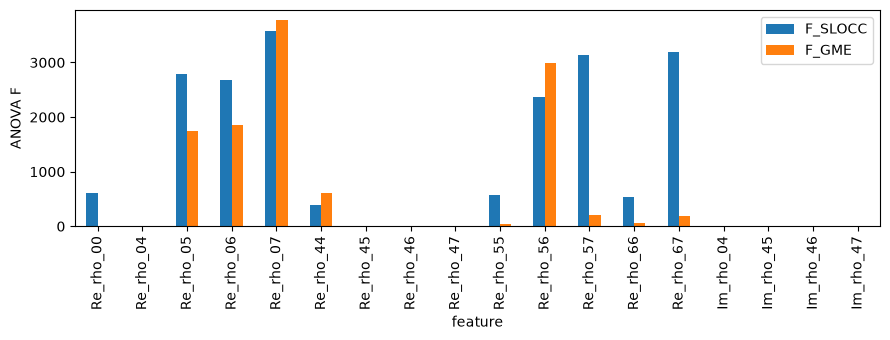

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.5))
t3.loc[features.CANONICAL_18].plot.bar(ax=ax); ax.set_ylabel('ANOVA F'); plt.tight_layout(); plt.show()